# Диффузионные модели: обзор

**Модуль 6. Генеративный ИИ**

Мы изучаем, как диффузионная модель обучается работать с зашумлёнными данными и как затем создаёт новые объекты, начиная со случайного шума.

Сначала разберём прямой и обратный процессы, затем выполним небольшой пример на точках с двумя координатами. Увидим добавление шума, обучение сети предсказывать шум и последовательную генерацию новых точек. В конце свяжем эту схему с моделями изображений, латентной диффузией и генерацией с условием.

Это обзор с выполненными примерами, без вывода математических формул и без заданий. Перед каждой кодовой ячейкой есть вводный абзац, после — разбор конструкций Python и результатов. Материал подходит для занятия и самостоятельного последовательного чтения.

Все вычисления выполняются на процессоре. Данные создаются локально; изображения, датасеты и готовые веса моделей не скачиваются. Для повторного запуска используется ядро **«Python — основы фреймворков ИИ»** и библиотеки PyTorch, NumPy, Pandas, Matplotlib, scikit-learn и **Diffusers 0.37.0**. Diffusers здесь нужен только для численных переходов DDPM.

## 1. От шума к новому объекту

### Прямой и обратный процессы

**Диффузионная модель** учится создавать данные с помощью последовательного изменения зашумлённого состояния. Рассмотрим вариант **DDPM** — *Denoising Diffusion Probabilistic Model*.

В **прямом процессе** к исходным объектам по известным правилам постепенно добавляют случайный шум и ослабляют исходный сигнал. При достаточно сильном зашумлении структура данных почти исчезает. Для этого процесса обученная сеть не нужна.

В **обратном процессе** обученная сеть помогает переходить от более шумного состояния к менее шумному. Генерация начинается с нового случайного шума. После серии переходов появляется объект, похожий по структуре на обучающие данные.

```text
Подготовка обучающих примеров:
исходный объект → добавление шума выбранного уровня → зашумлённый объект

Генерация после обучения:
новый случайный шум → обратный шаг → обратный шаг → ... → новый объект
```

«Обратный» не означает точное восстановление того же исходного объекта. Сильный шум скрывает информацию, и одна зашумлённая версия может быть совместима с разными исходными объектами. При генерации модель создаёт новый правдоподобный результат, а не отыскивает единственный оригинал.

Подход DDPM описан в [работе Ho, Jain и Abbeel](https://arxiv.org/abs/2006.11239). Наглядный обзор этапов есть в [курсе Hugging Face](https://huggingface.co/learn/diffusion-course/en/unit1/1).

### Что делает сеть, а что — планировщик

В нашем варианте сеть получает зашумлённый объект и номер уровня шума. Она **предсказывает добавленный шум**. Это один из распространённых вариантов цели; не все диффузионные модели предсказывают именно шум.

| Компонент | Его роль |
|---|---|
| Сеть предсказания шума | По текущему объекту и уровню оценивает шумовую составляющую |
| Расписание шума | Задаёт, как изменяется зашумление между уровнями |
| Планировщик, scheduler | Применяет правила добавления шума и обратных переходов |
| Сэмплирование | Весь процесс получения новых объектов после обучения |

Одна и та же сеть вызывается на разных уровнях. Для каждого уровня не создаётся новая нейросеть. Во время генерации параметры сети остаются постоянными — меняется обрабатываемый объект.

В отличие от разобранной GAN, в этом примере нет состязания генератора и дискриминатора. Обучающий ответ известен: это шум, который мы сами добавили.

Слово «планировщик» здесь относится к уровням шума и переходам между ними. Он не заменяет оптимизатор и не задаёт расписание шага обучения.

Подключим библиотеки, выберем процессор и создадим папку результатов. Используем готовый планировщик DDPM: он позволит сосредоточиться на смысле переходов, не реализуя численные выражения вручную.

In [1]:
import sys
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from sklearn.datasets import make_moons
import diffusers
from diffusers import DDPMScheduler

torch.set_num_threads(1)
device = torch.device("cpu")
result_dir = Path.cwd() / "16_результаты_диффузии"
result_dir.mkdir(exist_ok=True)
plt.rcParams["font.family"] = "DejaVu Sans"
pd.set_option("display.width", 120)
print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("Diffusers:", diffusers.__version__)
print("Устройство:", device)
print("Результаты:", result_dir)

Python: 3.13.13
PyTorch: 2.11.0+xpu
Diffusers: 0.37.0
Устройство: cpu
Результаты: C:\Users\user\Desktop\courses\shift\3928_Artificial_Intelligence_Specialist\16_результаты_диффузии


**Разбор кода**

- `import` подключает модуль; `as` задаёт короткое имя: `np`, `pd`, `plt`. `from ... import ...` подключает выбранный объект: `Path` для путей, `nn` для нейросетей, `make_moons` для синтетических данных и `DDPMScheduler` для переходов DDPM.
- `torch.set_num_threads(1)` ограничивает вычисления одним потоком: для маленькой сети этого достаточно. `torch.device("cpu")` описывает устройство. Текст в кавычках — строка Python.
- `=` сохраняет значение в переменной. `Path.cwd()` получает рабочую папку; оператор `/` у `Path` присоединяет имя подпапки.
- `mkdir(exist_ok=True)` создаёт папку и допускает, что она уже есть. `True` — логическое значение «истина».
- `plt.rcParams["font.family"]` выбирает шрифт с кириллицей. Доступ через квадратные скобки здесь использует текстовый ключ. `pd.set_option(...)` настраивает ширину вывода таблиц.
- `print(...)` выводит подписи и значения. Точка обращается к свойству или методу: `sys.version` содержит сведения о Python, `__version__` — версию библиотеки.
- `split()` разбивает строку по пробелам; `[0]` выбирает первый элемент. В Python индексация начинается с нуля.
- Импорт `DDPMScheduler` сам по себе не загружает готовую модель и не запускает обучение.

## 2. Данные, на которых виден смысл зашумления

Возьмём точки в форме двух дуг. Каждый объект — пара координат. Мы будем генерировать новые точки той же общей структуры; это не задача классификации дуг.

Обучающую выборку используем для обновления сети. Отдельная опорная выборка из того же синтетического источника нужна для рисунков и контроля ошибки предсказания шума. Она не участвует в обновлении параметров.

Создадим обе выборки локально и немного сместим координаты к центру плоскости. Вспомогательная функция будет единообразно показывать точки на всех рисунках. На первом рисунке отметим только обучающие данные.

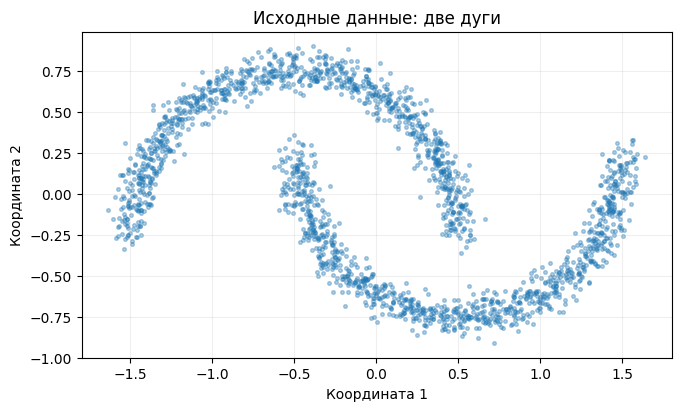

Обучающая выборка: (2048, 2)
Опорная выборка: (1000, 2)


In [2]:
train_array, _ = make_moons(n_samples=2048, noise=0.06, random_state=42)
reference_array, _ = make_moons(n_samples=1000, noise=0.06, random_state=43)
center_shift = torch.tensor([0.5, 0.25], device=device)
clean_points = torch.tensor(train_array, dtype=torch.float32, device=device) - center_shift
reference_points = torch.tensor(
    reference_array, dtype=torch.float32, device=device
) - center_shift

def draw_points(ax, points, title, color="tab:blue"):
    array = points.detach().cpu().numpy()
    ax.scatter(array[:, 0], array[:, 1], s=7, alpha=0.35, color=color)
    ax.set(title=title, xlabel="Координата 1", ylabel="Координата 2")
    ax.set_aspect("equal", adjustable="box")
    ax.grid(alpha=0.2)

fig, ax = plt.subplots(figsize=(7, 4), layout="constrained")
draw_points(ax, clean_points, "Исходные данные: две дуги")
fig.savefig(result_dir / "01_исходные_данные.png", dpi=150)
plt.show()
print("Обучающая выборка:", tuple(clean_points.shape))
print("Опорная выборка:", tuple(reference_points.shape))

**Разбор кода и результата**

- `make_moons(...)` создаёт синтетические координаты и метки дуг. `n_samples` задаёт число точек, `noise=0.06` — небольшой разброс, `random_state` — начальное состояние случайных чисел.
- В `train_array, _ = ...` два результата распаковываются в переменные. Имя `_` по соглашению обозначает ненужный результат: метки дуг нам не требуются.
- `torch.tensor(...)` превращает массив или список в тензор. `dtype=torch.float32` выбирает вещественные числа обычной точности, `device=device` — процессор.
- Вычитание `center_shift` смещает каждую пару координат на одинаковые значения. Тензор из двух чисел автоматически применяется ко всем строкам. Это перенос данных, а не выделение классов.
- `def draw_points(...)` определяет функцию. `color="tab:blue"` задаёт цвет по умолчанию. Двоеточие и отступы выделяют тело функции.
- `detach()` отделяет тензор от графа градиентов, `cpu()` размещает его на процессоре, `numpy()` получает массив для рисунка.
- `array[:, 0]` выбирает все строки и первую координату, `[:, 1]` — вторую. `scatter(...)` рисует точки; `s` задаёт размер, `alpha` — прозрачность, `color` — цвет.
- `set(...)` оформляет заголовок и оси. `set_aspect("equal", adjustable="box")` сохраняет одинаковый масштаб единицы по обеим осям. `grid(...)` добавляет сетку.
- `fig, ax = plt.subplots(...)` получает рисунок и область рисования. `figsize` задаёт размер, `layout="constrained"` размещает подписи. `draw_points(...)` заполняет область.
- `savefig(...)` сохраняет PNG, `dpi=150` задаёт разрешение; `plt.show()` выводит рисунок. `shape`, `tuple(...)` и `print(...)` показывают размеры: по две координаты на объект.

## 3. Прямой процесс: разные уровни шума

### Расписание и номер уровня

Уровень сообщает, насколько зашумлён объект. Сеть должна его знать: одинаковые координаты при слабом и сильном зашумлении требуют разных действий.

В нашем примере исходные данные соответствуют **уровню 0**, затем идут 200 уровней зашумления. Библиотека нумерует их индексами от **0 до 199**. Поэтому индекс `24` означает уровень `25`, а индекс `199` — уровень `200`. Чистый уровень 0 не является дополнительным обучаемым индексом.

Расписание настроим так, чтобы к последнему уровню вклад исходного объекта стал очень маленьким. Эти параметры выбраны для небольшого учебного примера и не являются настройками для любой модели изображений.

Создадим планировщик с 200 уровнями и посмотрим на несколько его коэффициентов. Таблица покажет, как ослабевает вклад исходного объекта. Коэффициент не следует читать как процент сохранённых пикселей или объектов.

In [3]:
diffusion_steps = 200
scheduler = DDPMScheduler(
    num_train_timesteps=diffusion_steps,
    beta_start=0.0005,
    beta_end=0.08,
    beta_schedule="linear",
    prediction_type="epsilon",
    variance_type="fixed_small",
    clip_sample=False,
)
inspected_indices = torch.tensor([0, 24, 74, 199], dtype=torch.long)
schedule_table = pd.DataFrame({
    "Индекс библиотеки": inspected_indices.tolist(),
    "Уровень шума": (inspected_indices + 1).tolist(),
    "Коэффициент исходного сигнала":
        scheduler.alphas_cumprod[inspected_indices].sqrt().tolist(),
})
print(schedule_table.round(4).to_string(index=False))

 Индекс библиотеки  Уровень шума  Коэффициент исходного сигнала
                 0             1                         0.9997
                24            25                         0.9358
                74            75                         0.5605
               199           200                         0.0160


**Разбор кода и результата**

- `DDPMScheduler(...)` создаёт объект планировщика без обученных весов. `num_train_timesteps` задаёт количество уровней, а не число обновлений параметров сети.
- `beta_start` и `beta_end` задают начальную и конечную интенсивность добавления шума на отдельных переходах; `beta_schedule="linear"` делает изменение этого параметра линейным. Накопленное зашумление при этом не обязано меняться линейно.
- `prediction_type="epsilon"` означает, что сеть будет предсказывать шум. Значение `variance_type="fixed_small"` выбирает используемый DDPM вариант случайности обратных переходов.
- `clip_sample=False` отключает обрезание оценки исходного объекта до стандартного диапазона. Для наших координат значения за пределами −1 и 1 допустимы.
- `torch.tensor([...], dtype=torch.long)` создаёт целочисленные индексы. `[...]` у `alphas_cumprod` выбирает соответствующие накопленные коэффициенты.
- `sqrt()` получает коэффициент, с которым исходный объект входит в зашумлённый. Численное вычисление выполняет библиотека; математический вывод для обзорной темы не нужен.
- `tolist()` переводит значения в списки. Прибавление `1` к индексам даёт номера уровней в объяснении.
- `pd.DataFrame({...})` создаёт таблицу из словаря: ключи становятся названиями столбцов, списки — их значениями. `round(4)` округляет, `to_string(index=False)` скрывает служебные индексы, `print(...)` выводит таблицу.
- На последнем уровне коэффициент исходного сигнала примерно `0.016`. Он мал, но не равен нулю: начало генерации из обычного случайного шума здесь является приближением.

Покажем исходные точки и три уровня их зашумления. Метод добавит нужное количество шума сразу, без выполнения всех предыдущих переходов. Панели являются отдельными примерами состояний разных уровней, а не последовательностью одной случайной траектории.

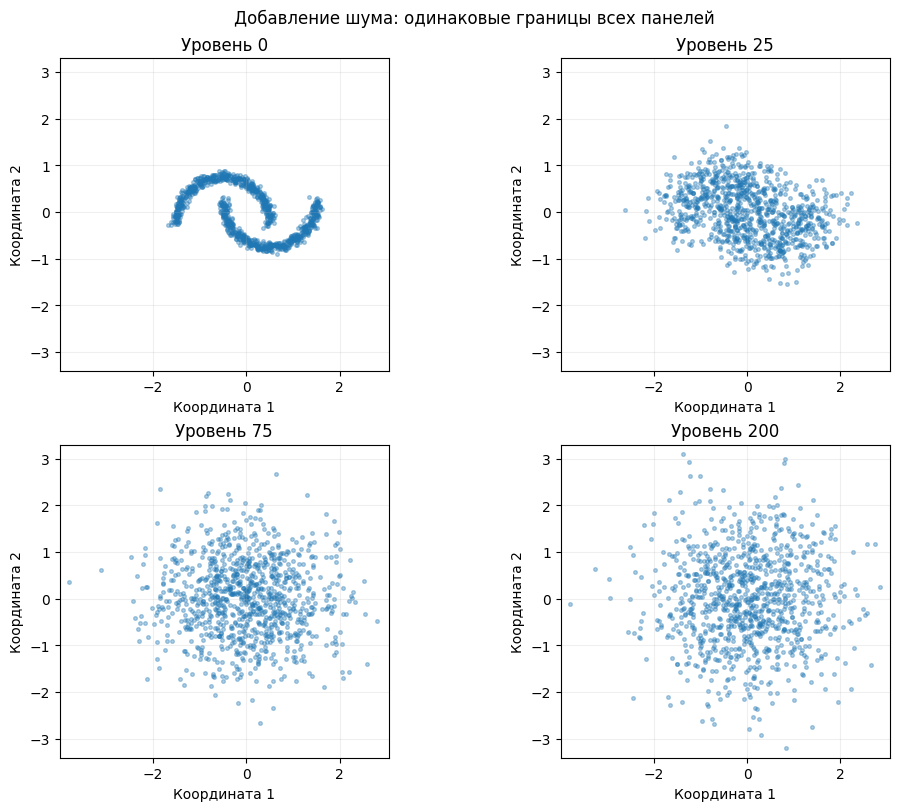

In [4]:
forward_rng = torch.Generator(device=device).manual_seed(50)
forward_examples = {0: reference_points}
for level in (25, 75, 200):
    timesteps = torch.full(
        (len(reference_points),), level - 1, dtype=torch.long, device=device
    )
    noise = torch.randn(reference_points.shape, generator=forward_rng, device=device)
    forward_examples[level] = scheduler.add_noise(reference_points, noise, timesteps)

all_forward = torch.cat(list(forward_examples.values()), dim=0)
lower = all_forward.min(dim=0).values - 0.2
upper = all_forward.max(dim=0).values + 0.2
fig, axes = plt.subplots(2, 2, figsize=(10, 8), layout="constrained")
for ax, (level, points) in zip(axes.flat, forward_examples.items()):
    draw_points(ax, points, f"Уровень {level}")
    ax.set_xlim(lower[0].item(), upper[0].item())
    ax.set_ylim(lower[1].item(), upper[1].item())
fig.suptitle("Добавление шума: одинаковые границы всех панелей")
fig.savefig(result_dir / "02_уровни_шума.png", dpi=150)
plt.show()

**Разбор кода и результата**

- `torch.Generator(...).manual_seed(50)` создаёт воспроизводимый источник случайных чисел. Он не является обучаемой моделью.
- `{0: reference_points}` создаёт словарь с чистым уровнем. Цикл `for level in (25, 75, 200)` перебирает три числа из кортежа.
- `torch.full((len(reference_points),), level - 1, ...)` создаёт по одному одинаковому индексу для каждой точки. `len(...)` считает строки, `(число,)` — кортеж размера из одного элемента.
- `torch.randn(reference_points.shape, ...)` создаёт шум той же формы, что и координаты. `shape` содержит размеры. На каждой итерации получаются новые случайные значения.
- `scheduler.add_noise(исходные, шум, индексы)` получает зашумлённую выборку выбранных уровней. `forward_examples[level] = ...` сохраняет её по ключу.
- `values()` получает значения словаря, `list(...)` превращает их в список, `torch.cat(..., dim=0)` объединяет строки. `min(dim=0).values` и `max(dim=0).values` находят общие границы координат.
- `plt.subplots(2, 2, ...)` создаёт четыре панели. `axes.flat` перебирает их по строкам; `items()` даёт пары «уровень, точки»; `zip(...)` связывает каждую пару с панелью.
- `draw_points(...)` рисует данные. В `f"Уровень {level}"` фигурные скобки подставляют значение переменной в строку.
- `set_xlim(...)` и `set_ylim(...)` задают одинаковые границы; `item()` извлекает число из тензора. `suptitle(...)` добавляет общий заголовок, `savefig(...)` сохраняет, `plt.show()` отображает.
- При росте уровня дуги становятся неразличимыми в облаке. Ни одна сеть при создании этих панелей ещё не обучалась.

## 4. Чему учится сеть

### Как получить обучающий ответ без ручной разметки

Для одного обучающего примера нужны исходная точка, случайно выбранный уровень и случайный шум. Из них планировщик получает зашумлённую точку. Сеть видит **зашумлённую точку и уровень**, а целевой ответ — **сам добавленный шум**.

Исходная точка нужна для подготовки примера, но не передаётся сети в качестве дополнительного входа. Во время генерации у нас вообще не будет исходной точки.

В одном пакете могут встречаться разные уровни. Поэтому на обучающей итерации не требуется проходить цепочку из 200 вызовов сети. Полная последовательность обратных вызовов понадобится после обучения, при создании объектов.

Подготовим четыре демонстрационных примера и покажем входы и ответы в таблице. Последние два столбца — значения, которые сеть должна научиться предсказывать. Для каждого объекта уровень выбирается отдельно.

In [5]:
demo_rng = torch.Generator(device=device).manual_seed(55)
demo_indices = torch.randint(len(clean_points), (4,), generator=demo_rng, device=device)
demo_steps = torch.randint(
    0, diffusion_steps, (4,), generator=demo_rng, device=device
)
demo_noise = torch.randn(4, 2, generator=demo_rng, device=device)
demo_noisy = scheduler.add_noise(clean_points[demo_indices], demo_noise, demo_steps)
training_example_table = pd.DataFrame({
    "Уровень": (demo_steps + 1).tolist(),
    "Вход: координата 1": demo_noisy[:, 0].tolist(),
    "Вход: координата 2": demo_noisy[:, 1].tolist(),
    "Ответ: шум 1": demo_noise[:, 0].tolist(),
    "Ответ: шум 2": demo_noise[:, 1].tolist(),
})
print(training_example_table.round(3).to_string(index=False))

 Уровень  Вход: координата 1  Вход: координата 2  Ответ: шум 1  Ответ: шум 2
      14              -0.917               0.387        -0.094        -1.777
      94              -0.227              -0.749        -0.307        -0.535
      70               0.928              -0.591         0.443        -0.338
     158              -0.619               1.261        -0.682         1.318


**Разбор кода**

- `torch.Generator(...).manual_seed(55)` создаёт отдельный источник случайности для показа.
- `torch.randint(len(clean_points), (4,), ...)` выбирает четыре индекса исходных строк; верхняя граница не включается, повторения возможны. Вариант `torch.randint(0, diffusion_steps, (4,), ...)` выбирает четыре индекса уровней.
- `torch.randn(4, 2, ...)` создаёт по два значения шума на точку. `clean_points[demo_indices]` выбирает строки по тензору индексов.
- `scheduler.add_noise(...)` готовит входы сети из выбранных точек, шума и уровней.
- `pd.DataFrame({...})` строит таблицу из словаря. Двоеточие связывает название столбца со значениями; запятые разделяют записи.
- Срезы `[:, 0]` и `[:, 1]` выбирают координаты или составляющие шума. `tolist()` превращает столбцы в списки. Выражение `demo_steps + 1` переводит индексы в номера уровней.
- `round(3)` округляет таблицу для вывода, `to_string(index=False)` исключает служебный индекс, `print(...)` показывает результат.
- Сеть не должна отвечать «первая или вторая дуга». Её ответ здесь — два вещественных значения шума.

Создадим маленькую сеть и постоянный набор для контроля её ошибки. На входе сети будут две зашумлённые координаты и один номер уровня, приведённый к небольшому числовому диапазону. Сравним необученную сеть с простым ответом «шум равен нулю».

In [6]:
class NoisePredictor(nn.Module):
    def __init__(self, num_timesteps=200, hidden_size=64):
        super().__init__()
        self.num_timesteps = num_timesteps
        self.layers = nn.Sequential(
            nn.Linear(3, hidden_size),
            nn.SiLU(),
            nn.Linear(hidden_size, hidden_size),
            nn.SiLU(),
            nn.Linear(hidden_size, 2),
        )

    def forward(self, noisy_points, timesteps):
        time_column = (timesteps.float().unsqueeze(1) + 1) / self.num_timesteps
        inputs = torch.cat([noisy_points, time_column], dim=1)
        return self.layers(inputs)

torch.manual_seed(61)
model = NoisePredictor(num_timesteps=diffusion_steps).to(device)
loss_function = nn.MSELoss()
validation_rng = torch.Generator(device=device).manual_seed(88)
validation_steps = torch.randint(
    0, diffusion_steps, (1000,), generator=validation_rng, device=device
)
validation_noise = torch.randn(1000, 2, generator=validation_rng, device=device)
validation_noisy = scheduler.add_noise(
    reference_points, validation_noise, validation_steps
)
with torch.no_grad():
    error_before = loss_function(
        model(validation_noisy, validation_steps), validation_noise
    ).item()
    zero_baseline = loss_function(
        torch.zeros_like(validation_noise), validation_noise
    ).item()
print("Параметров сети:", sum(p.numel() for p in model.parameters()))
print("Ошибка до обучения:", round(error_before, 4))
print("Ошибка нулевого прогноза:", round(zero_baseline, 4))

Параметров сети: 4546
Ошибка до обучения: 0.9554
Ошибка нулевого прогноза: 0.9762


**Разбор кода и результата**

- `class NoisePredictor(nn.Module)` определяет собственный класс сети. `def` создаёт методы, `self` обозначает текущий экземпляр. `__init__` запускается при его создании.
- `super().__init__()` подготавливает базовый `nn.Module`. `self.num_timesteps` сохраняет настройку, `self.layers` — последовательность слоёв.
- `nn.Sequential(...)` применяет слои по очереди. `nn.Linear(3, hidden_size)` получает три входных признака. `nn.SiLU()` — гладкая активация между слоями; выходной `nn.Linear(hidden_size, 2)` возвращает две составляющие шума без ограничения диапазона.
- `forward(...)` определяет обработку входа. `timesteps.float()` переводит целые индексы в вещественные числа; `unsqueeze(1)` превращает одномерный набор в столбец.
- Прибавление `1` получает номер уровня, деление на `self.num_timesteps` приводит его к диапазону до единицы. `torch.cat([...], dim=1)` присоединяет этот столбец к двум координатам. `return self.layers(inputs)` возвращает прогноз.
- `torch.manual_seed(61)` задаёт состояние для начальных параметров. `NoisePredictor(...)` создаёт сеть, `to(device)` размещает её на процессоре.
- `nn.MSELoss()` создаёт функцию среднеквадратичной ошибки. Здесь она сравнивает предсказанный и известный шум; повторный вывод метрики не требуется.
- `torch.Generator(...).manual_seed(88)`, `torch.randint(...)` и `torch.randn(...)` создают неизменный контрольный набор уровней и шума. `scheduler.add_noise(...)` зашумляет опорные точки.
- В `with torch.no_grad()` прогноз `model(...)` вычисляется без графа градиентов. `loss_function(...)` получает прогноз и ответ; `item()` извлекает число. `torch.zeros_like(...)` создаёт нулевой прогноз той же формы.
- `parameters()` перебирает обучаемые тензоры, `numel()` считает элементы; `sum(... for p in ...)` складывает количества. `round(...)` и `print(...)` выводят размер сети и ошибки. Пока сеть не обучалась.

**Полученный результат.** В сети **4546 обучаемых параметров**. До обучения MSE шума составляет примерно **0,955**, а у нулевого прогноза — **0,976**. Случайная сеть ещё не даёт полезного устойчивого предсказания; близость этих двух чисел не означает, что она уже научилась удалять шум.

### Обучение по случайным уровням

Будем сравнивать прогноз с известным шумом и обновлять одну сеть одним оптимизатором. При каждом обновлении заново выбираются исходные строки, уровни и шум. Контрольный набор остаётся неизменным, поэтому изменения контрольной ошибки связаны с сетью.

Различаем два числа: **4000 обновлений параметров** в обучении и **200 уровней шума**. Увеличение числа уровней не добавляет автоматически обучающих итераций.

Потеря предсказания шума — рабочий показатель обучения, но не полная оценка качества сгенерированных данных. Для её чтения используется знакомая [MSELoss из PyTorch](https://docs.pytorch.org/docs/2.11/generated/torch.nn.MSELoss.html).

Обучим сеть на случайных пакетах из 256 объектов. Каждые 200 обновлений сохраним обучающую и контрольную ошибки. Контроль выполняется без изменения параметров и без новых случайных входов.

In [7]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
training_rng = torch.Generator(device=device).manual_seed(77)
training_updates = 4000
batch_size = 256
history_rows = []
model.train()

for update in range(1, training_updates + 1):
    indices = torch.randint(
        len(clean_points), (batch_size,), generator=training_rng, device=device
    )
    timesteps = torch.randint(
        0, diffusion_steps, (batch_size,), generator=training_rng, device=device
    )
    target_noise = torch.randn(
        batch_size, 2, generator=training_rng, device=device
    )
    noisy_batch = scheduler.add_noise(clean_points[indices], target_noise, timesteps)
    optimizer.zero_grad(set_to_none=True)
    prediction = model(noisy_batch, timesteps)
    loss = loss_function(prediction, target_noise)
    loss.backward()
    optimizer.step()

    if update == 1 or update % 200 == 0:
        with torch.no_grad():
            validation_error = loss_function(
                model(validation_noisy, validation_steps), validation_noise
            ).item()
        history_rows.append({
            "Обновление": update,
            "Ошибка пакета": loss.item(),
            "Контрольная ошибка": validation_error,
        })

model.eval()
history = pd.DataFrame(history_rows)
error_after = history.iloc[-1]["Контрольная ошибка"]
print(history.iloc[[0, 5, 10, -1]].round(4).to_string(index=False))

 Обновление  Ошибка пакета  Контрольная ошибка
          1         1.0229              0.9334
       1000         0.2534              0.2454
       2000         0.2052              0.2365
       4000         0.2663              0.2336


**Разбор кода**

- `torch.optim.Adam(model.parameters(), lr=0.001)` создаёт оптимизатор для параметров одной сети. `lr` задаёт шаг обучения. `torch.Generator(...).manual_seed(77)` отделяет случайность обучения от демонстраций.
- `history_rows = []` создаёт пустой список. `train()` включает режим обучения. В этой сети нет Dropout и Batch Normalization, поэтому контрольные вызовы без смены режима дают тот же численный результат.
- `range(1, training_updates + 1)` выдаёт номера от 1 до 4000 включительно; правая граница не включается. Цикл `for` повторяет блок с отступом.
- `torch.randint(...)` выбирает индексы строк и уровней, `len(...)` задаёт размер выборки. `torch.randn(...)` создаёт шум. Повторения строк в пакете возможны.
- `clean_points[indices]` выбирает исходные точки. `scheduler.add_noise(...)` создаёт зашумлённый пакет из них, целевого шума и уровней.
- `zero_grad(set_to_none=True)` очищает старые градиенты, `model(...)` предсказывает шум. `loss_function(...)` сравнивает прогноз с `target_noise`. `backward()` вычисляет градиенты, `step()` меняет параметры.
- `if` выполняет условный блок; `==` сравнивает значения, `%` находит остаток деления, `or` означает «хотя бы одно условие». Журнал записывается на первом обновлении и затем каждые 200.
- `with torch.no_grad()` отключает граф при контроле. `item()` извлекает числовую ошибку, `append({...})` добавляет словарь в список.
- `eval()` включает режим использования, не отключая градиенты автоматически. `pd.DataFrame(...)` создаёт журнал.
- `iloc[-1]` выбирает последнюю строку по позиции; `["Контрольная ошибка"]` получает столбец. `iloc[[0, 5, 10, -1]]` выбирает четыре строки для показа. `round(4)`, `to_string(index=False)` и `print(...)` оформляют вывод.

Сопоставим ошибки с простым нулевым прогнозом и покажем ход обучения. У обучающей ошибки меняются пакеты и уровни, поэтому она может колебаться. Контрольная ошибка вычислена на одном и том же наборе.

             Вариант    MSE
Нулевой прогноз шума 0.9762
    Сеть до обучения 0.9554
 Сеть после обучения 0.2336


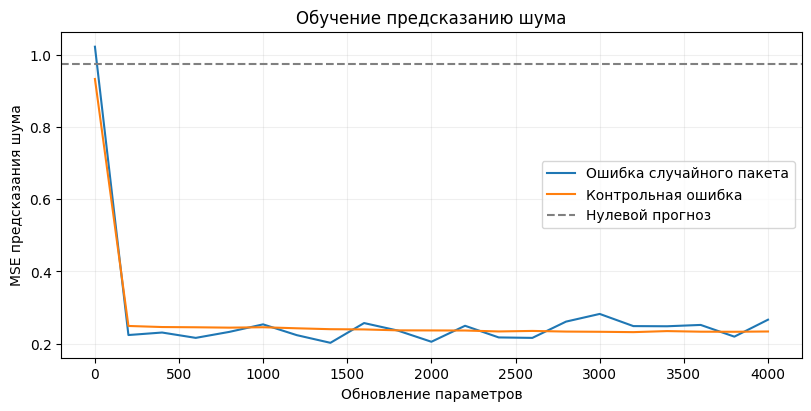

In [8]:
error_comparison = pd.DataFrame([
    {"Вариант": "Нулевой прогноз шума", "MSE": zero_baseline},
    {"Вариант": "Сеть до обучения", "MSE": error_before},
    {"Вариант": "Сеть после обучения", "MSE": error_after},
])
print(error_comparison.round(4).to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 4), layout="constrained")
ax.plot(history["Обновление"], history["Ошибка пакета"], label="Ошибка случайного пакета")
ax.plot(history["Обновление"], history["Контрольная ошибка"], label="Контрольная ошибка")
ax.axhline(zero_baseline, color="gray", linestyle="--", label="Нулевой прогноз")
ax.set(
    title="Обучение предсказанию шума",
    xlabel="Обновление параметров", ylabel="MSE предсказания шума"
)
ax.grid(alpha=0.2)
ax.legend()
fig.savefig(result_dir / "03_обучение.png", dpi=150)
plt.show()

**Разбор кода и результата**

- `pd.DataFrame([...])` создаёт таблицу из трёх словарей. Каждый словарь — строка с названием варианта и значением ошибки.
- `round(4)` округляет числа; `to_string(index=False)` и `print(...)` показывают таблицу.
- `plt.subplots(...)` создаёт рисунок и оси. `plot(...)` строит линии: первый аргумент задаёт позиции по горизонтали, второй — значения ошибки. Доступ `history["..."]` выбирает столбец.
- `axhline(...)` добавляет горизонтальную линию нулевого прогноза. `linestyle="--"` делает её пунктирной; `label` задаёт подпись.
- `set(...)` оформляет заголовок и оси, `grid(...)` добавляет сетку, `legend()` — легенду.
- `savefig(...)` сохраняет рисунок, `plt.show()` выводит.
- Ошибка обученной сети должна быть ниже ошибки нулевого прогноза: сеть использует связь зашумлённого объекта с исходной структурой. Это ещё не доказывает, что новые объекты воспроизводят все особенности двух дуг.

**Разбор полученных чисел.** После 4000 обновлений контрольная MSE шума составляет примерно **0,234**, против **0,955** до обучения и **0,976** у нулевого прогноза. На графике основное снижение происходит в начале, далее изменения небольшие. Это подтверждает обучение прогнозу, но ничего не говорит о полном совпадении новых точек с исходными дугами без просмотра генерации.

### Оценка чистого объекта и следующий обратный шаг — разные результаты

По прогнозу шума планировщик может вычислить **оценку полностью чистого объекта**. Это полезно для предварительного просмотра. Но следующий обратный шаг обычно не заменяет текущий объект этой оценкой напрямую: переход учитывает текущий уровень, расписание и, в DDPM, дополнительную случайность.

В ответе планировщика есть два разных поля:

| Поле | Смысл |
|---|---|
| `pred_original_sample` | Оценка чистого объекта по текущему состоянию |
| `prev_sample` | Состояние после одного обратного перехода; именно его передают в следующий вызов сети |

Различие описано в [документации DDPMScheduler 0.37.0](https://huggingface.co/docs/diffusers/v0.37.0/en/api/schedulers/ddpm). Слепое вычитание всего предсказанного шума или многократная подача одного уровня не заменяют согласованную последовательность переходов.

Возьмём умеренно зашумлённые опорные точки уровня 25 и получим оценку чистых координат. В этом диагностическом примере исходные точки известны, поэтому можно сравнить ошибку до и после обработки. Для генерации далее исходные точки использоваться не будут.

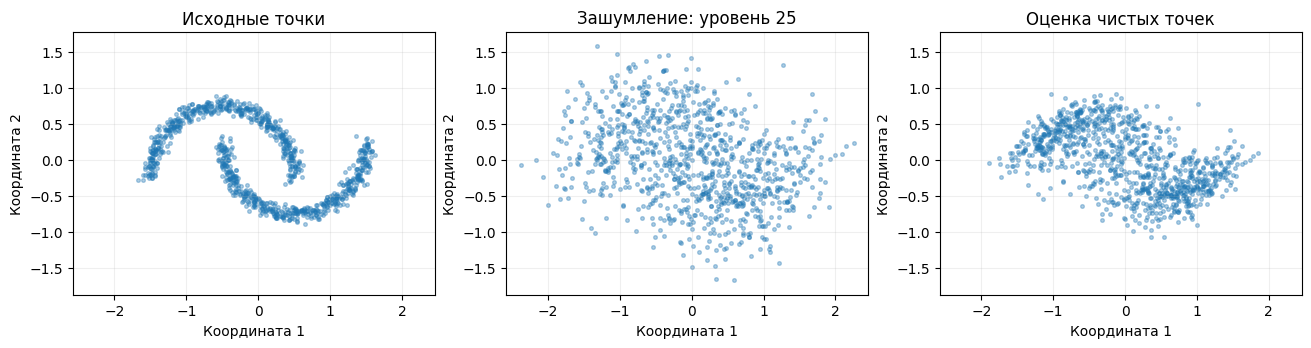

MSE координат до обработки: 0.1256
MSE координат после оценки: 0.0903


In [9]:
scheduler.set_timesteps(diffusion_steps, device=device)
preview_rng = torch.Generator(device=device).manual_seed(111)
preview_index = 24
preview_steps = torch.full(
    (len(reference_points),), preview_index, dtype=torch.long, device=device
)
preview_noise = torch.randn(
    reference_points.shape, generator=preview_rng, device=device
)
preview_noisy = scheduler.add_noise(reference_points, preview_noise, preview_steps)
with torch.no_grad():
    preview_prediction = model(preview_noisy, preview_steps)
    preview_result = scheduler.step(
        preview_prediction, preview_index, preview_noisy, generator=preview_rng
    )
    clean_estimate = preview_result.pred_original_sample
    coordinate_error_before = loss_function(preview_noisy, reference_points).item()
    coordinate_error_after = loss_function(clean_estimate, reference_points).item()

preview_sets = [reference_points, preview_noisy, clean_estimate]
preview_titles = ["Исходные точки", "Зашумление: уровень 25", "Оценка чистых точек"]
combined = torch.cat(preview_sets, dim=0)
lower = combined.min(dim=0).values - 0.2
upper = combined.max(dim=0).values + 0.2
fig, axes = plt.subplots(1, 3, figsize=(13, 4), layout="constrained")
for ax, points, title in zip(axes, preview_sets, preview_titles):
    draw_points(ax, points, title)
    ax.set_xlim(lower[0].item(), upper[0].item())
    ax.set_ylim(lower[1].item(), upper[1].item())
fig.savefig(result_dir / "04_оценка_чистых_точек.png", dpi=150)
plt.show()
print("MSE координат до обработки:", round(coordinate_error_before, 4))
print("MSE координат после оценки:", round(coordinate_error_after, 4))

**Разбор кода и результата**

- `set_timesteps(diffusion_steps, ...)` задаёт полную последовательность из 200 обратных переходов для планировщика. Здесь она нужна для корректной работы его `step(...)`.
- `torch.Generator(...).manual_seed(111)` задаёт случайность показа. `preview_index = 24` соответствует уровню 25.
- `torch.full(...)` создаёт по одному индексу на объект; `len(...)` считает объекты. `torch.randn(...)` создаёт шум, `scheduler.add_noise(...)` готовит зашумлённые точки.
- В `torch.no_grad()` вызов `model(...)` предсказывает шум. `scheduler.step(прогноз, индекс, текущие_точки, ...)` вычисляет обратный переход и оценку исходных точек.
- `preview_result.pred_original_sample` выбирает оценку чистого объекта. Поле `prev_sample` здесь не используется: мы изучаем предварительный просмотр, а не продолжаем генерацию.
- `loss_function(...)` сравнивает координаты с известными исходными. `item()` извлекает число. Это **MSE координат**, а в журнале выше была **MSE шума**; смысл сравниваемых объектов различается.
- `preview_sets` и `preview_titles` — параллельные списки данных и названий. `torch.cat(...)` объединяет строки для границ; `min(...).values` и `max(...).values` выбирают крайние координаты.
- `plt.subplots(1, 3, ...)` создаёт три панели, `zip(...)` связывает панель, данные и заголовок. Цикл вызывает `draw_points(...)`, `set_xlim(...)` и `set_ylim(...)` с общими границами.
- `savefig(...)` и `plt.show()` сохраняют и выводят рисунок; `round(...)` и `print(...)` показывают ошибки.
- Даже после улучшения координат точное возвращение каждой точки на её исходное место не гарантируется. Модель использует изученную структуру и может давать усреднённую оценку при неоднозначности.

**Полученный результат.** MSE координат уменьшилась примерно с **0,126** до **0,090**. На правой панели облако стало компактнее, но две узкие исходные дуги не восстановлены точно. Сеть предсказывает полезную поправку, сохраняя неоднозначность и ошибки; показанная оценка не является возвращением всех исходных точек на прежние места.

## 5. Генерация начинается с нового шума

Теперь сеть не получает опорную или обучающую точку. Начальное состояние — 1000 новых случайных пар чисел.

На каждом шаге выполняются три действия: сеть предсказывает шум на текущем уровне, планировщик вычисляет следующий объект, полученный объект становится новым входом. Индекс уменьшается от 199 до 0. После перехода с индексом 0 получаем итоговый уровень 0.

Наш планировщик DDPM в большинстве обратных переходов добавляет новую небольшую случайную составляющую. Это часть выбранного алгоритма сэмплирования, а не повторное обучение сети. Поэтому для воспроизводимости нужно фиксировать источник случайности всей цепочки, а не только начального облака.

Опишем полный цикл генерации и сразу создадим 1000 точек. Планировщик для каждого запуска создаётся из тех же настроек; обученные параметры сети не меняются. Сохраним промежуточные состояния, чтобы увидеть возникновение структуры.

In [10]:
def sample_points(model, base_scheduler, count, seed):
    local_scheduler = DDPMScheduler.from_config(base_scheduler.config)
    total_steps = local_scheduler.config.num_train_timesteps
    local_scheduler.set_timesteps(total_steps, device=device)
    rng = torch.Generator(device=device).manual_seed(seed)
    current = torch.randn(count, 2, generator=rng, device=device)
    snapshots = {total_steps: current.clone()}
    model.eval()
    with torch.no_grad():
        for timestep in local_scheduler.timesteps:
            index = int(timestep.item())
            step_batch = torch.full(
                (count,), index, dtype=torch.long, device=device
            )
            predicted_noise = model(current, step_batch)
            result = local_scheduler.step(
                predicted_noise, index, current, generator=rng
            )
            current = result.prev_sample
            if index in (150, 100, 50, 0):
                snapshots[index] = current.clone()
    return current, snapshots

parameters_before_sampling = {
    name: parameter.detach().clone()
    for name, parameter in model.named_parameters()
}
generated_points, reverse_snapshots = sample_points(model, scheduler, count=1000, seed=99)
print("Создано объектов:", len(generated_points))
print("Размер результата:", tuple(generated_points.shape))
print("Сохранённые уровни:", list(reverse_snapshots))

Создано объектов: 1000
Размер результата: (1000, 2)
Сохранённые уровни: [200, 150, 100, 50, 0]


**Разбор кода**

- `def sample_points(...)` создаёт функцию с сетью, планировщиком, количеством объектов и начальным состоянием случайных чисел.
- `DDPMScheduler.from_config(base_scheduler.config)` создаёт новый планировщик с теми же настройками. `config.num_train_timesteps` получает число уровней. `set_timesteps(...)` задаёт все обратные переходы без пропусков.
- `torch.Generator(...).manual_seed(seed)` фиксирует случайность запуска. `torch.randn(count, 2, ...)` создаёт начальное облако. `clone()` сохраняет независимую копию.
- `model.eval()` включает режим использования, `torch.no_grad()` отключает построение графа. Оптимизатор внутри функции не вызывается.
- `for timestep in local_scheduler.timesteps` перебирает убывающие индексы. `item()` извлекает скаляр из тензора, `int(...)` превращает его в целое число.
- `torch.full((count,), index, ...)` повторяет текущий индекс для всех объектов. `model(current, step_batch)` предсказывает шум.
- `local_scheduler.step(...)` получает прогноз, индекс и текущие координаты; `generator=rng` задаёт случайность перехода. `current = result.prev_sample` заменяет текущий объект результатом одного перехода.
- `if index in (...)` проверяет принадлежность кортежу. Ключ снимка — уже полученный **уровень**: после перехода с индексом 150 остаётся уровень 150, после индекса 0 — чистый уровень 0.
- `return current, snapshots` возвращает итог и словарь снимков. Присваивание `generated_points, reverse_snapshots = ...` распаковывает их.
- `named_parameters()` перебирает имена и параметры. Включение словаря `{... for ...}` сохраняет копии через `detach().clone()`, чтобы далее проверить неизменность весов.
- `len(...)`, `shape` и `tuple(...)` показывают размер; `list(reverse_snapshots)` получает ключи словаря; `print(...)` выводит проверки.

Покажем сохранённые этапы обратного процесса и опорные данные для сравнения. На всех панелях будут одинаковые границы. Промежуточные уровни — реальные состояния генерации, а не картинки, полученные смешиванием готового результата с шумом.

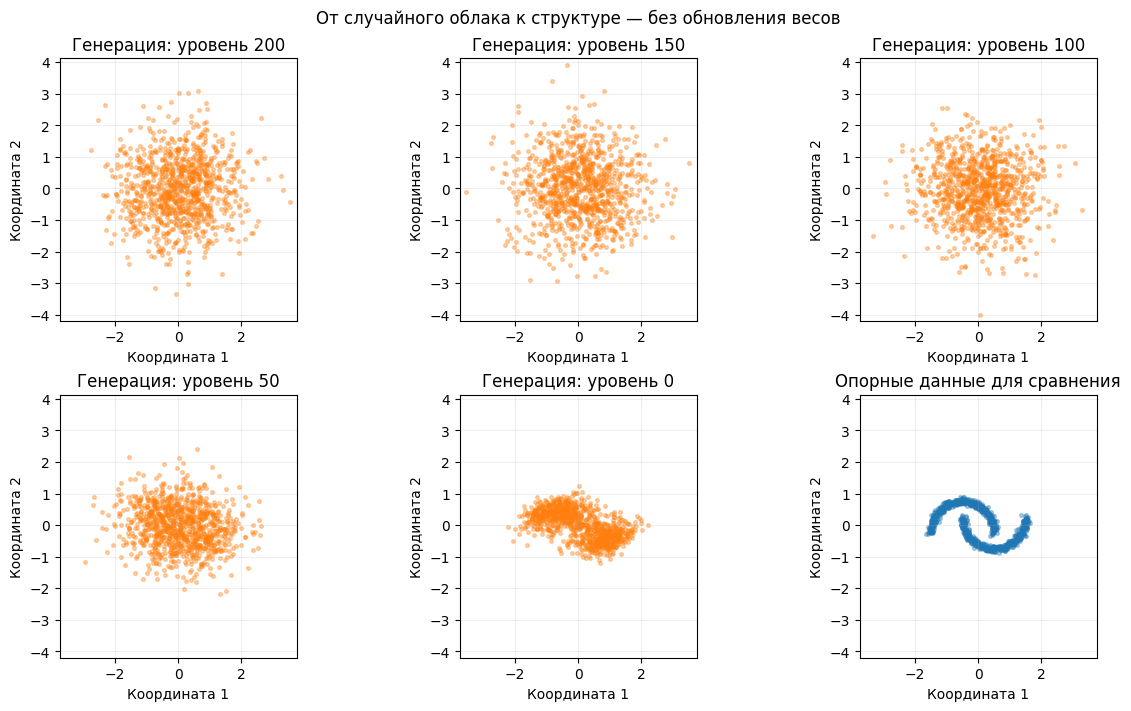

In [11]:
reverse_levels = [200, 150, 100, 50, 0]
combined = torch.cat(
    [reference_points] + [reverse_snapshots[level] for level in reverse_levels], dim=0
)
lower = combined.min(dim=0).values - 0.2
upper = combined.max(dim=0).values + 0.2
fig, axes = plt.subplots(2, 3, figsize=(12, 7), layout="constrained")
for ax, level in zip(axes.flat, reverse_levels):
    draw_points(ax, reverse_snapshots[level], f"Генерация: уровень {level}", color="tab:orange")
draw_points(axes.flat[5], reference_points, "Опорные данные для сравнения")
for ax in axes.flat:
    ax.set_xlim(lower[0].item(), upper[0].item())
    ax.set_ylim(lower[1].item(), upper[1].item())
fig.suptitle("От случайного облака к структуре — без обновления весов")
fig.savefig(result_dir / "05_обратный_процесс.png", dpi=150)
plt.show()

**Разбор кода и результата**

- `reverse_levels` — список уровней в порядке генерации. Списковое включение `[reverse_snapshots[level] for level in reverse_levels]` собирает соответствующие тензоры.
- `[reference_points] + [...]` объединяет списки, а `torch.cat(..., dim=0)` объединяет строки тензоров. Это нужно только для определения общих границ.
- `min(dim=0).values`, `max(dim=0).values` находят крайние координаты, отступ `0.2` оставляет поля.
- `plt.subplots(2, 3, ...)` создаёт шесть панелей. `axes.flat` перебирает их по строкам; `zip(...)` объединяет первые пять панелей с уровнями.
- `draw_points(...)` показывает снимок, `f"...{level}"` подставляет номер в заголовок. `color="tab:orange"` выбирает оранжевый цвет.
- `axes.flat[5]` — шестая панель: в ней показаны опорные данные. Они не передавались функции генерации.
- Второй цикл по панелям вызывает `set_xlim(...)`, `set_ylim(...)`. `item()` получает числовые границы.
- `suptitle(...)` добавляет общий заголовок; `savefig(...)` сохраняет рисунок, `plt.show()` отображает.
- Сначала точки напоминают облако, затем появляется вытянутая структура. Итог не обязан идеально повторять узкие дуги: маленькая сеть и короткое обучение демонстрируют механизм, сохраняя видимые погрешности.

**Что видно на этапах.** На уровнях 200 и 150 остаётся широкое случайное облако. Ближе к уровню 0 оно сжимается и приобретает вытянутую структуру, напоминающую расположение дуг. Однако итог заметно шире исходных полос. Маленькая сеть научилась части структуры, а точное воспроизведение формы этим запуском не достигнуто.

### Повторяемость и новые варианты

В одной и той же версии библиотек, на том же устройстве и с теми же настройками повторный запуск с тем же seed должен повторять результат. Другой seed меняет случайные значения всей цепочки и позволяет получать новые объекты без переобучения.

Seed не является содержательным описанием объекта и не заменяет текстовое условие. Между разными устройствами или версиями библиотек он не гарантирует полного совпадения результатов.

Повторим генерацию с seed 99 и создадим ещё одну выборку с seed 100. Проверим повторяемость и неизменность параметров сети. На двух рисунках сопоставим новые точки с опорными; видимые отклонения также являются частью результата.

Одинаковый seed повторяет результат: True
Другой seed изменяет результат: True
Генерация сохранила параметры сети: True


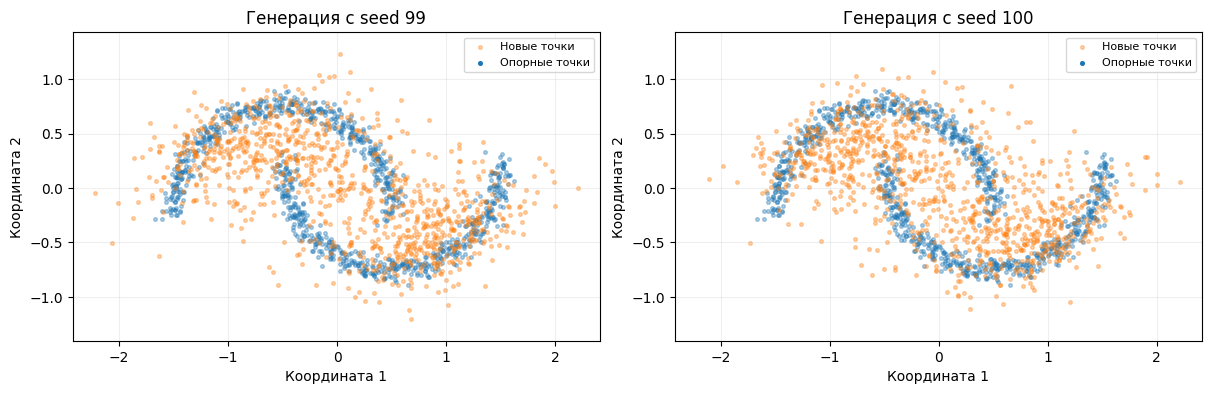

In [12]:
repeated_points, _ = sample_points(model, scheduler, count=1000, seed=99)
other_points, _ = sample_points(model, scheduler, count=1000, seed=100)
same_seed_matches = torch.allclose(generated_points, repeated_points)
different_seed_changes = not torch.allclose(generated_points, other_points)
weights_unchanged = all(
    torch.equal(parameter.detach(), parameters_before_sampling[name])
    for name, parameter in model.named_parameters()
)
print("Одинаковый seed повторяет результат:", same_seed_matches)
print("Другой seed изменяет результат:", different_seed_changes)
print("Генерация сохранила параметры сети:", weights_unchanged)

combined = torch.cat([reference_points, generated_points, other_points], dim=0)
lower = combined.min(dim=0).values - 0.2
upper = combined.max(dim=0).values + 0.2
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
for ax, points, seed in zip(axes, [generated_points, other_points], [99, 100]):
    draw_points(ax, reference_points, f"Генерация с seed {seed}")
    ax.scatter(
        points[:, 0].numpy(), points[:, 1].numpy(),
        s=7, alpha=0.35, color="tab:orange", label="Новые точки"
    )
    ax.scatter([], [], s=7, color="tab:blue", label="Опорные точки")
    ax.set_xlim(lower[0].item(), upper[0].item())
    ax.set_ylim(lower[1].item(), upper[1].item())
    ax.legend(fontsize=8)
fig.savefig(result_dir / "06_новые_выборки.png", dpi=150)
plt.show()

**Разбор кода и результата**

- `sample_points(...)` повторяет весь обратный процесс. Через `repeated_points, _` и `other_points, _` сохраняем итоги, а дополнительные снимки не используем.
- `torch.allclose(...)` проверяет близость тензоров с небольшим числовым допуском. `not` меняет логический результат на противоположный.
- `model.named_parameters()` даёт пары имени и параметра. `parameter.detach()` отделяет параметр от графа, `torch.equal(...)` сравнивает его со снимком. `all(... for ...)` требует равенства для всех параметров.
- `print(...)` показывает три проверки: повторяемость одного seed, изменение результата другого и сохранение весов.
- `torch.cat(...)`, `min(...).values` и `max(...).values` определяют общие границы рисунков. `plt.subplots(1, 2, ...)` создаёт две панели.
- `zip(...)` связывает панель, выборку и seed. `draw_points(...)` показывает опорные точки, а строка `f"...{seed}"` подписывает запуск.
- `scatter(...)` добавляет новые точки. `[:, 0]` и `[:, 1]` выбирают координаты, `numpy()` получает массивы.
- `scatter([], [], ...)` создаёт только элемент легенды для опорных данных: два пустых списка не рисуют дополнительные объекты. `label` задаёт подпись.
- `set_xlim(...)`, `set_ylim(...)` задают границы; `item()` извлекает числа, `legend(...)` показывает легенду. `savefig(...)` сохраняет, `plt.show()` выводит рисунок.
- Разные числовые результаты ещё не доказывают хорошее разнообразие и качество. Здесь важен совместный просмотр формы, разброса и точек за пределами исходных дуг.

**Полученный результат.** Все три проверки равны `True`: один seed повторяет результат, другой создаёт новую выборку, а параметры сети во время генерации не меняются. На обеих панелях есть лишние точки между дугами и за их границами. Это видимое ограничение выбранной модели; снижение ошибки предсказания шума не устранило его автоматически.

## 6. Сохранение сети вместе с настройками процесса

Для повторной генерации нужны параметры сети, её архитектура и согласованные настройки планировщика. Число уровней и тип предсказываемого ответа относятся к этому согласованию.

Сохраним комплект для генерации, журнал и координаты. Это не полный снимок для продолжения обучения: состояния оптимизатора и обучающего генератора случайных чисел в него не входят.

Сохраним сеть и конфигурацию планировщика отдельно, а рядом — небольшие таблицы и описание примера. Последующая загрузка будет читать только эти локальные файлы. Повторное выполнение материала обновит результаты под теми же именами.

In [13]:
model_path = result_dir / "сеть_предсказания_шума.pt"
scheduler_dir = result_dir / "планировщик_DDPM"
torch.save({
    "model_state": model.state_dict(),
    "num_timesteps": diffusion_steps,
    "hidden_size": 64,
}, model_path)
scheduler.save_config(scheduler_dir)
history.to_csv(result_dir / "журнал_обучения.csv", index=False, encoding="utf-8-sig")
pd.DataFrame(
    generated_points.numpy(), columns=["Координата 1", "Координата 2"]
).to_csv(result_dir / "новые_точки.csv", index=False, encoding="utf-8-sig")
metadata = {
    "тема": "Диффузионные модели: обзор на синтетических точках",
    "вариант": "DDPM, предсказание шума, без условия",
    "данные": "две дуги make_moons, локальная генерация",
    "обучающих_точек": len(clean_points),
    "опорных_точек": len(reference_points),
    "уровней_шума": diffusion_steps,
    "обновлений_параметров": training_updates,
    "объектов_в_пакете": batch_size,
    "MSE_нулевого_прогноза": zero_baseline,
    "MSE_до_обучения": error_before,
    "MSE_после_обучения": float(error_after),
    "seed_генерации": 99,
    "повторяемость": same_seed_matches,
    "веса_при_генерации_не_менялись": weights_unchanged,
    "готовые_веса_не_загружались": True,
    "версия_Diffusers": diffusers.__version__,
    "назначение": "генерация, не продолжение обучения",
}
(result_dir / "описание_примера.json").write_text(
    json.dumps(metadata, ensure_ascii=False, indent=2), encoding="utf-8"
)
print("Сеть:", model_path.name)
print("Размер файла сети, байт:", model_path.stat().st_size)
print("Планировщик:", scheduler_dir.name)

Сеть: сеть_предсказания_шума.pt
Размер файла сети, байт: 21013
Планировщик: планировщик_DDPM


**Разбор кода**

- Оператор `/` присоединяет имя к пути. `torch.save({...}, model_path)` записывает словарь в файл.
- `model.state_dict()` возвращает именованные параметры сети. В словаре вместе с ними сохранены настройки архитектуры `num_timesteps` и `hidden_size`.
- `scheduler.save_config(...)` сохраняет конфигурацию планировщика в локальную подпапку. Сам планировщик не содержит обученных весов.
- `to_csv(...)` записывает таблицы. `index=False` исключает служебные номера строк; `encoding="utf-8-sig"` помогает открывать кириллицу в табличных программах.
- `pd.DataFrame(..., columns=[...])` подписывает два столбца координат. `numpy()` получает массив из результата генерации без градиентов.
- `metadata` — словарь сведений о примере. `len(...)` записывает размеры выборок, `float(error_after)` получает обычное число Python. `True` — логическое подтверждение факта, `diffusers.__version__` — версия библиотеки.
- `json.dumps(...)` преобразует словарь в текст JSON; `ensure_ascii=False` сохраняет читаемую кириллицу, `indent=2` задаёт отступы.
- `write_text(..., encoding="utf-8")` сохраняет описание. `name` получает имя файла или папки, `stat().st_size` — размер файла в байтах. `print(...)` показывает созданные объекты.

Восстановим сеть и планировщик в новые объекты и повторим генерацию с seed 99. Проверим весь результат цепочки, а не только выход сети на одном входе. Это подтвердит согласованное сохранение обоих компонентов.

In [14]:
saved = torch.load(model_path, map_location=device, weights_only=True)
restored_model = NoisePredictor(
    num_timesteps=saved["num_timesteps"], hidden_size=saved["hidden_size"]
).to(device)
restored_model.load_state_dict(saved["model_state"])
restored_model.eval()
scheduler_config = json.loads(
    (scheduler_dir / "scheduler_config.json").read_text(encoding="utf-8")
)
restored_scheduler = DDPMScheduler.from_config(scheduler_config)
restored_points, _ = sample_points(
    restored_model, restored_scheduler, count=1000, seed=99
)
restore_matches = torch.allclose(generated_points, restored_points)
print("Восстановленная цепочка повторяет результат:", restore_matches)
print(pd.DataFrame(
    restored_points[:5].numpy(), columns=["Координата 1", "Координата 2"]
).round(3).to_string(index=False))

Восстановленная цепочка повторяет результат: True
 Координата 1  Координата 2
        0.966        -0.764
       -0.736         0.330
        0.661        -0.668
        0.349        -0.388
       -0.651         0.838


**Разбор кода и результата**

- `torch.load(...)` читает наш файл сети. `map_location=device` размещает параметры на процессоре; `weights_only=True` использует ограниченный режим загрузки параметров и простых структур.
- `saved["..."]` получает значения по ключам словаря. `NoisePredictor(...)` создаёт сеть нужной архитектуры, `to(device)` выбирает устройство.
- `load_state_dict(...)` подставляет обученные параметры. `eval()` переводит новую сеть в режим использования.
- `read_text(encoding="utf-8")` читает локальную конфигурацию. `json.loads(...)` превращает JSON-текст в словарь. `DDPMScheduler.from_config(...)` создаёт планировщик по этому словарю, без обращения к хранилищу моделей.
- `sample_points(...)` выполняет весь обратный процесс. Второй результат обозначен `_`, потому что новые снимки здесь не нужны.
- `torch.allclose(...)` сравнивает восстановленные точки с сохранённым результатом исходной цепочки; ожидается `True`.
- `restored_points[:5]` выбирает первые пять строк, `numpy()` получает массив. `pd.DataFrame(...)` подписывает координаты, `round(3)` округляет, `to_string(index=False)` убирает индекс. `print(...)` выводит проверку и примеры.

**Полученный результат.** Восстановленная цепочка повторяет исходные 1000 точек при том же seed: проверка вернула `True`. Восстановлены и параметры сети, и настройки переходов; дальнейшее обучение для этой проверки не потребовалось.

## 7. Как перейти от точек к изображениям

### Пространство пикселей и латентное представление

Наш объект содержит два числа. У изображения таких значений намного больше: сеть должна учитывать пространственное расположение, детали и связи между частями изображения.

В **пиксельной диффузии** зашумляются сами массивы пикселей. В **латентной диффузии** отдельная модель сначала кодирует изображение в более компактное числовое представление. Диффузионный процесс работает с этим представлением, а декодер переводит полученный результат обратно в пиксели.

```text
Обучение латентной диффузии:
изображение → кодировщик → компактное представление → добавление шума

Генерация:
шум в пространстве представлений → обратные шаги → декодер → изображение
```

Латентное представление — обученное кодирование изображения, а не просто уменьшенная картинка и не текст запроса. В зависимости от системы кодировщик и декодер подготавливаются отдельным этапом. В нашем примере такого компонента нет: точки зашумляются непосредственно.

Подход подробно представлен в [работе о latent diffusion](https://arxiv.org/abs/2112.10752).

### Архитектура сети и условие генерации

**U-Net** — распространённая архитектура сети обработки зашумлённых изображений: она уменьшает и затем восстанавливает пространственное разрешение, передавая признаки между соответствующими уровнями. Диффузионная модель не обязана использовать именно U-Net. Например, **Diffusion Transformer, DiT**, применяет трансформер к участкам представления изображения; это показано в [работе Peebles и Xie](https://arxiv.org/abs/2212.09748).

При **генерации с условием** сеть дополнительно получает класс, представление текста или другую информацию. Условие влияет на предсказания в обратных шагах. Текстовый кодировщик, когда он используется, преобразует текст в признаки; при этом роли текстового кодировщика и сети удаления шума различаются.

Один из способов усилить влияние условия — **classifier-free guidance**: при генерации согласованно объединяются предсказания с условием и без него. Он не требует отдельного классификатора, но предполагает подходящую подготовку модели. Усиление условия связано с компромиссом между соответствием, качеством и разнообразием, а не с гарантированным улучшением. Метод описан в [исходной работе о classifier-free guidance](https://arxiv.org/abs/2207.12598).

Наша сеть **безусловная**: ей нельзя передать текст или указать нужную дугу. Добавление строки в вызов Python само по себе не создаст такую возможность. Работа с конкретными средствами генерации изображений и текстовыми запросами относится к следующим темам.

## 8. Что означают настройки и где заканчивается пример

### Обучение и использование имеют разные настройки

| Настройка | Где действует | Что меняет |
|---|---|---|
| Обновления параметров | Обучение | Сколько раз оптимизатор изменит сеть |
| Расписание шума | Подготовка обучения и согласованная генерация | Связь уровней с зашумлением |
| Число обратных шагов | Генерация | Сколько переходов выполнит алгоритм |
| Seed | Генерация и другие случайные операции | Выбранную последовательность случайных значений |
| Условие и сила guidance | Подходящая условная модель | Направление генерации и влияние условия |

В нашем коде выполняются все 200 обратных переходов DDPM. Уменьшение их количества требует согласованного изменения алгоритма переходов. Нельзя ускорить этот цикл, просто оставив несколько прежних индексов и сохранив правила для соседних уровней.

Есть методы сэмплирования, рассчитанные на другие последовательности переходов. Например, [DDIM](https://arxiv.org/abs/2010.02502) позволяет использовать совместимую обученную модель с другим обратным процессом и исследовать компромисс скорости и качества. Выбор метода должен соответствовать модели; произвольная подмена настроек не гарантирует корректную генерацию. Фраза «чем больше шагов, тем обязательно лучше» также неверна.

### Как оценить увиденное

В примере проверены снижение ошибки предсказания шума, возникновение структуры при генерации, повторяемость в одном окружении и загрузка сохранённой цепочки. Эти проверки отвечают на разные вопросы.

Для оценки результата нужны сами новые объекты: их форма, разнообразие, характерные ошибки и отклонения от исходных данных. Небольшая MSE шума не доказывает точного воспроизведения всех особенностей выборки. Один удачный объект не характеризует всю модель.

Диффузионные модели могут создавать правдоподобные, но ошибочные детали. Возможность генерировать объект не означает точного восстановления скрытой информации. Ограничения зависят от данных, подготовки модели, архитектуры и способа использования.

Выполненный пример демонстрирует механизм DDPM на небольших данных. Он не является обученной системой изображений, а сравнение с GAN из прошлого материала не служит экспериментом о том, какой класс моделей лучше: данные, цели и настройки различаются.